This notebook plots the results of notebook 03: how the linear probe trained, how each method's setting was chosen, and how well each of the 6 models (2 methods × 3 feature sets) predicts crops on the held-out test blocks, overall, by country and by crop. Three scores are shown: accuracy (share of fields labelled correctly), recall (share of each crop's fields found, averaged over crops, also called mean recall or balanced accuracy) and F1 (balances recall with precision, averaged over crops, also called macro F1).

In [18]:
import numpy as np
import pandas as pd
import ultraplot as uplt
from pathlib import Path
from sklearn.metrics import f1_score,recall_score

In [19]:
INTERIMDIR  = Path('../data/interim')
PROCDIR     = Path('../data/processed')
FIGDIR      = Path('../figs')
COLLECTIONS = pd.read_csv(INTERIMDIR/'collections.csv')
NAMES       = dict(zip(COLLECTIONS.collection.str.split('/').str[1],COLLECTIONS.name.str.replace(r'\s*\(.*\)$','',regex=True)))
METHODS     = {'probe':'Linear Probe','knn':'kNN'}
FEATURESETS = {'olmoearth':'OlmoEarth','aef':'AEF','both':'Both'}
COLORS      = {'olmoearth':'#eb6834','aef':'#2a78d6','both':'#1baf7a'}
METRICS     = {'accuracy':'Accuracy','meanrecall':'Recall','macrof1':'F1'}
TOPCROPS    = 25

FIGDIR.mkdir(parents=True,exist_ok=True)

In [20]:
predictions = pd.read_parquet(INTERIMDIR/'results_predictions.parquet').assign(country=lambda table:table.country.map(NAMES))
losses      = pd.read_csv(PROCDIR/'results_probelosses.csv')
probesweep  = pd.read_csv(PROCDIR/'results_probesweep.csv')
knnsweep    = pd.read_csv(PROCDIR/'results_knnsweep.csv')
models      = [(method,featureset) for method in METHODS for featureset in FEATURESETS]

In [21]:
def score(group,method,featureset):
    truth,pred = group.crop,group[f'{method}_{featureset}']
    crops      = truth.unique()
    return {'accuracy':(truth==pred).mean(),
            'meanrecall':recall_score(truth,pred,labels=crops,average='macro',zero_division=0),
            'macrof1':f1_score(truth,pred,labels=crops,average='macro',zero_division=0)}

scores = pd.DataFrame([{'country':country,'method':method,'featureset':featureset,**score(group,method,featureset)}
                       for country,group in [('All countries',predictions)]+list(predictions.groupby('country')) for method,featureset in models])
scores.to_csv(PROCDIR/'results_scores.csv',index=False)

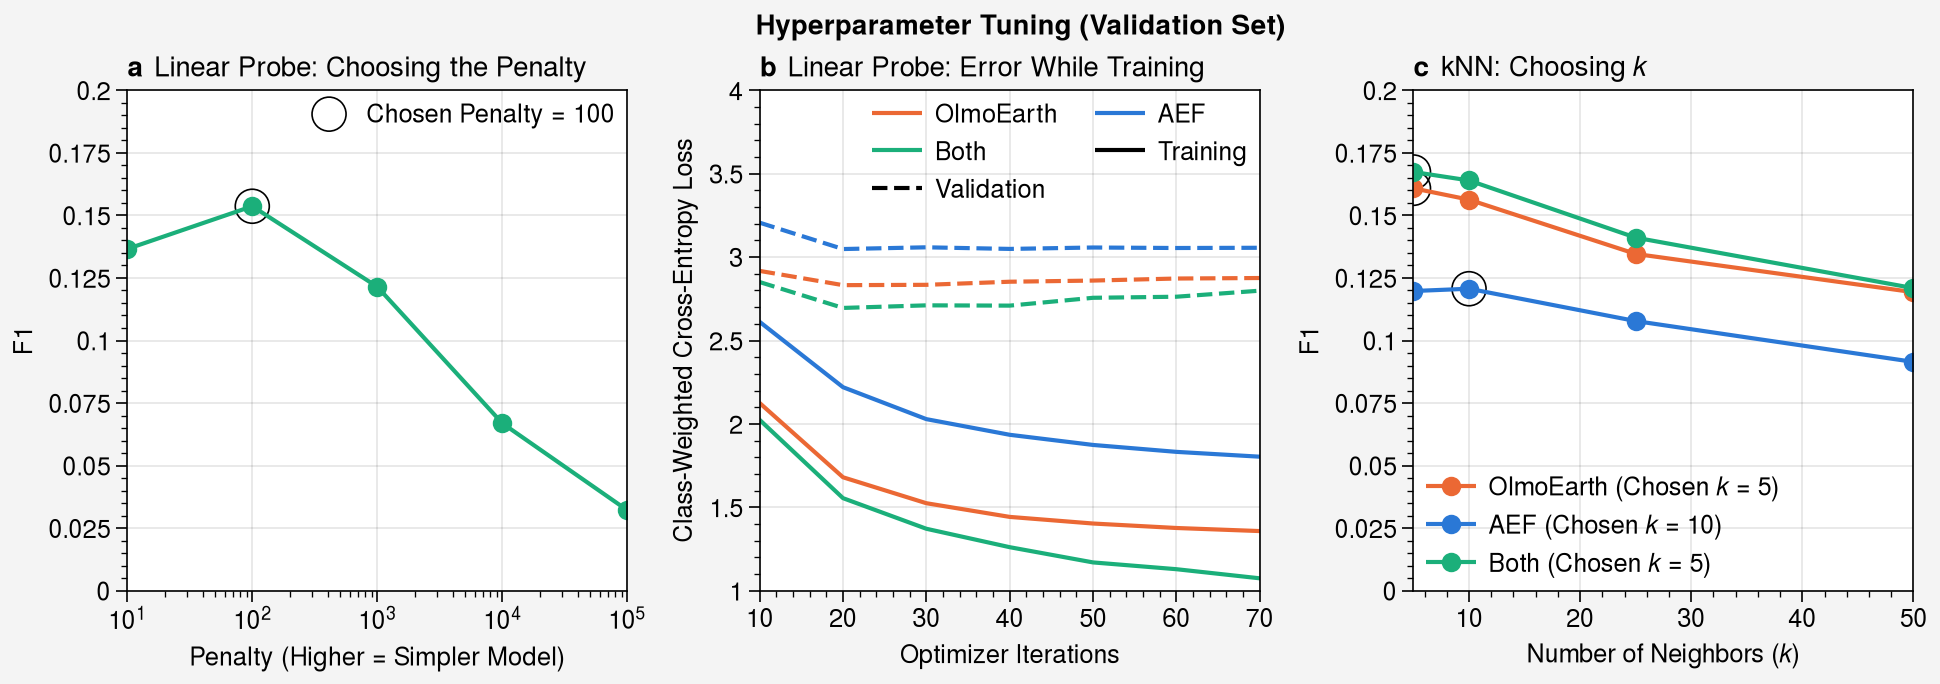

In [59]:
PENALTY = probesweep.loc[probesweep.valmacrof1.idxmax(),'penalty']
bestk   = knnsweep.loc[knnsweep.groupby('featureset').valmacrof1.idxmax()].set_index('featureset').k

fig,axs = uplt.subplots(ncols=3,share=False)
axs.format(abc='a',abcloc='l',titleloc='l',suptitle='Hyperparameter Tuning (Validation Set)')

axs[0].plot(probesweep.penalty.to_numpy(),probesweep.valmacrof1.to_numpy(),color=COLORS['both'],marker='o')
axs[0].scatter([PENALTY],probesweep.loc[probesweep.penalty==PENALTY,'valmacrof1'].to_numpy(),s=150,facecolor='none',edgecolor='k',label=f'Chosen Penalty = {PENALTY:,}')
axs[0].format(title='Linear Probe: Choosing the Penalty',xlabel='Penalty (Higher = Simpler Model)',xscale='log',xformatter='log',
              ylabel='F1',ylim=(0,0.2))
axs[0].legend(loc='ur',ncols=1,frame=False)

for featureset,label in FEATURESETS.items():
    curve = losses.query("stage=='final' and featureset==@featureset")
    axs[1].plot(curve.iterations.to_numpy(),curve.trainloss.to_numpy(),color=COLORS[featureset],label=label)
    axs[1].plot(curve.iterations.to_numpy(),curve.valloss.to_numpy(),color=COLORS[featureset],linestyle='--')
axs[1].plot([],[],color='k',label='Training')
axs[1].plot([],[],color='k',linestyle='--',label='Validation')
axs[1].format(title='Linear Probe: Error While Training',xlabel='Optimizer Iterations',ylabel='Class-Weighted Cross-Entropy Loss',ylim=(1,4))
axs[1].legend(loc='ur',ncols=2,frame=False)

for featureset,label in FEATURESETS.items():
    sweep = knnsweep.query('featureset==@featureset')
    axs[2].plot(sweep.k.to_numpy(),sweep.valmacrof1.to_numpy(),color=COLORS[featureset],marker='o',label=f'{label} (Chosen $k$ = {bestk[featureset]})')
    axs[2].scatter([bestk[featureset]],sweep.loc[sweep.k==bestk[featureset],'valmacrof1'].to_numpy(),s=150,facecolor='none',edgecolor='k')
axs[2].format(title='kNN: Choosing $k$',xlabel='Number of Neighbors ($k$)',ylabel='F1',ylim=(0,0.2))
axs[2].legend(loc='ll',ncols=1,frame=False)

fig.savefig(FIGDIR/'training_and_selection.png',dpi=200)

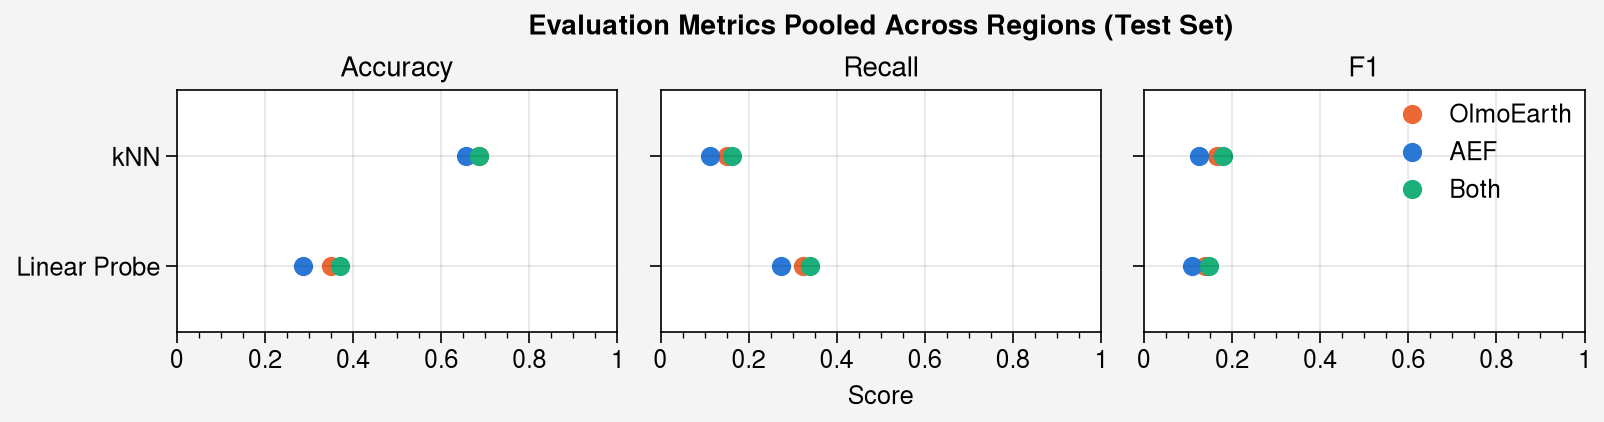

In [69]:
overall   = scores[scores.country=='All countries']
positions = {method:position for position,method in enumerate(METHODS)}

fig,axs = uplt.subplots(ncols=3,refwidth=2.2,refheight=1.2,share=True)
for ax,(metric,label) in zip(axs,METRICS.items()):
    for featureset,name in FEATURESETS.items():
        subset = overall[overall.featureset==featureset]
        ax.scatter(subset[metric].to_numpy(),subset.method.map(positions).to_numpy(),color=COLORS[featureset],label=name,s=40)
    ax.format(title=label)
axs.format(xlabel='Score',ylabel='',xlim=(0,1),ylim=(-0.6,1.6),yticks=list(positions.values()),
           yticklabels=list(METHODS.values()),ytickminor=False,ygrid=True)
axs[2].legend(loc='ur',ncols=1,frame=False)
fig.format(suptitle='Evaluation Metrics Pooled Across Regions (Test Set)')
fig.savefig(FIGDIR/'scores_overall.png',dpi=200)

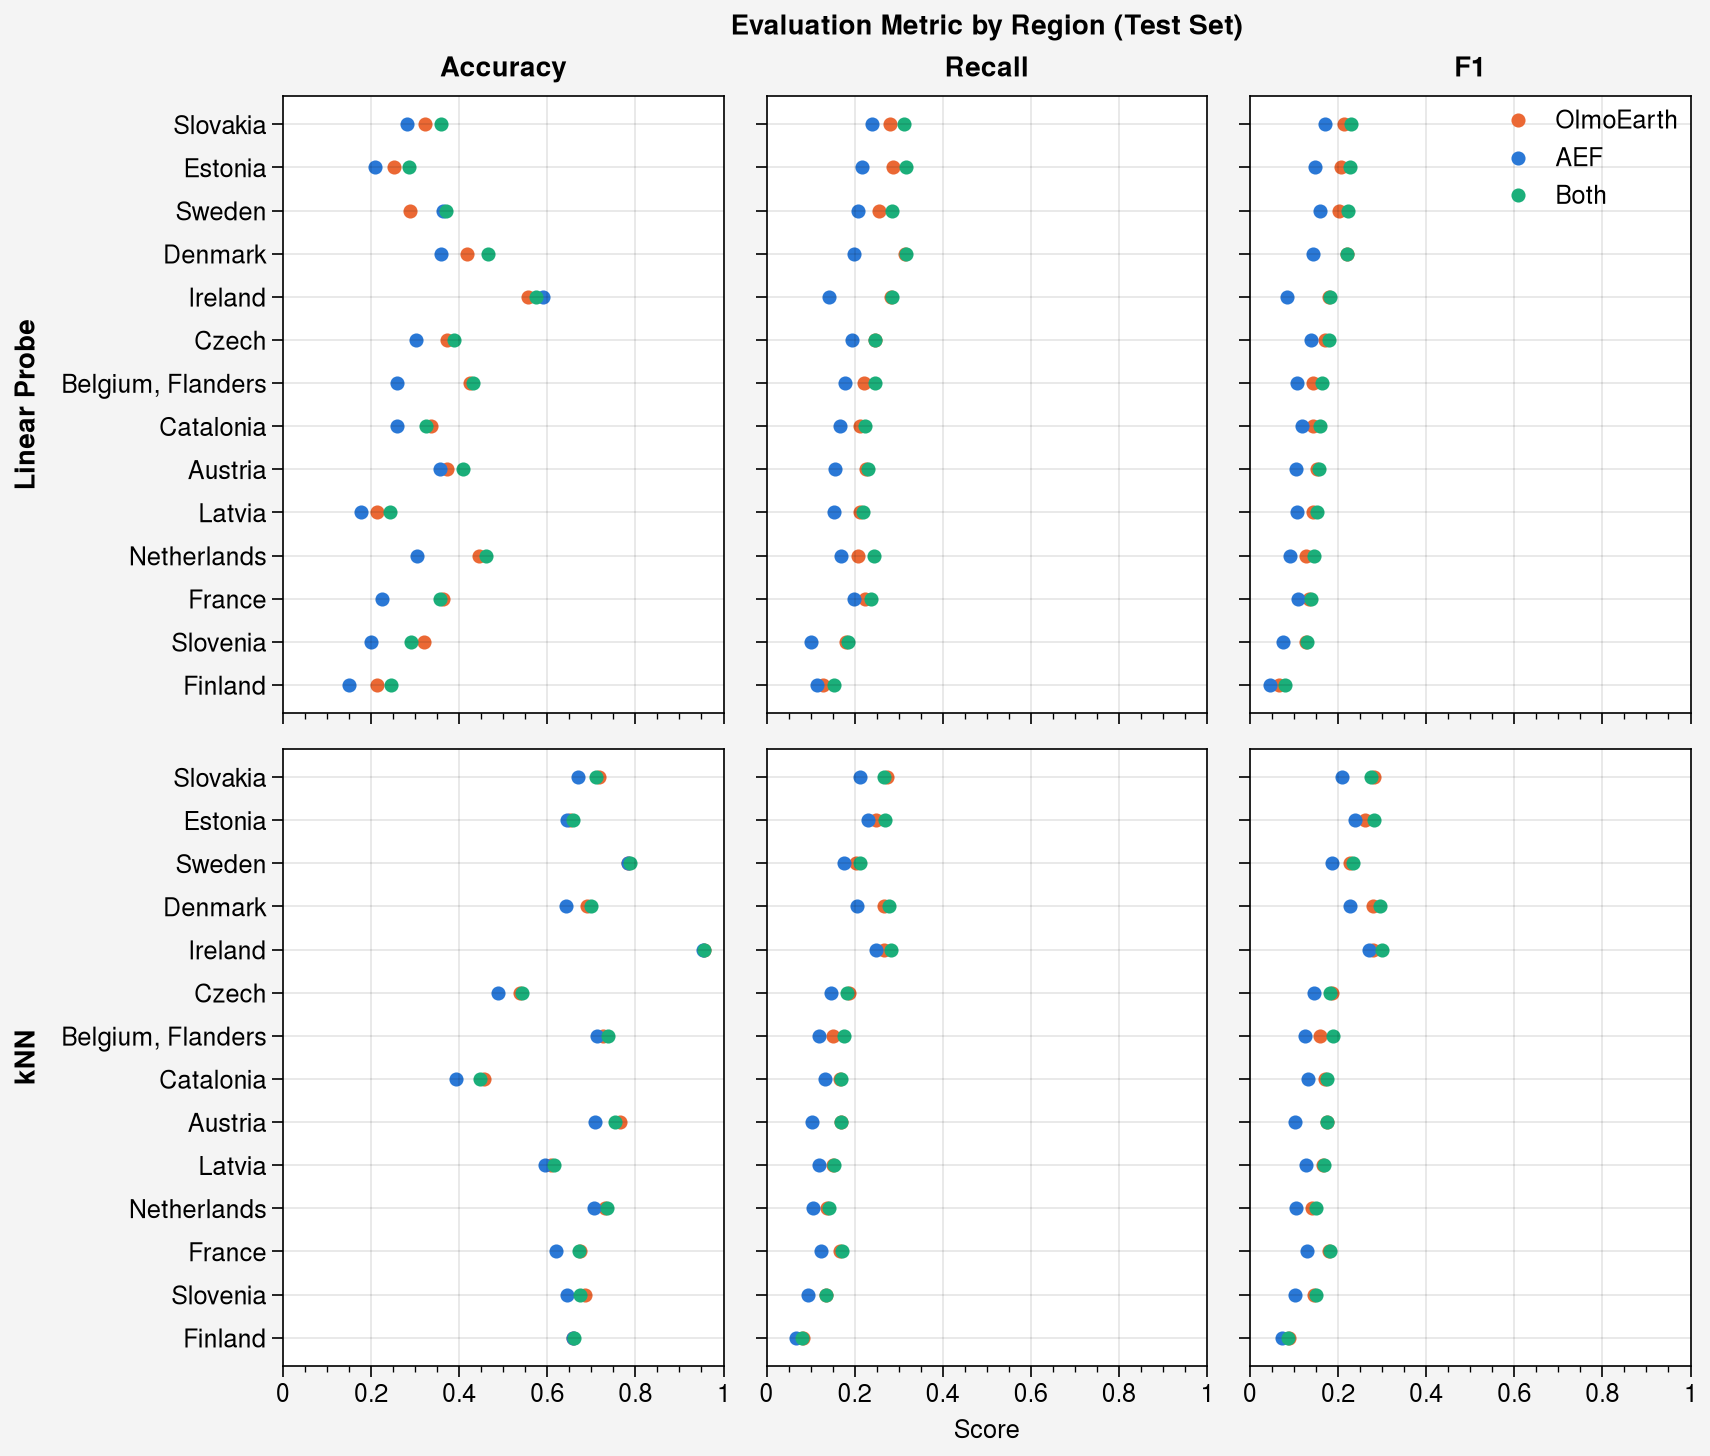

In [70]:
bycountry = scores[scores.country!='All countries']
order     = bycountry.query("method=='probe' and featureset=='both'").sort_values('macrof1').country.tolist()

fig,axs = uplt.subplots(nrows=2,ncols=3,refwidth=2.2,refheight=0.22*len(order),sharey=True,sharex=True)
for row,method in enumerate(METHODS):
    for col,metric in enumerate(METRICS):
        for featureset,name in FEATURESETS.items():
            subset = bycountry[(bycountry.method==method)&(bycountry.featureset==featureset)].set_index('country').loc[order]
            axs[row,col].scatter(subset[metric].to_numpy(),subset.index.to_numpy(),color=COLORS[featureset],label=name,s=20)
axs.format(xlim=(0,1),xlabel='Score',ylabel='',ygrid=True,toplabels=list(METRICS.values()),leftlabels=list(METHODS.values()),
           suptitle='Evaluation Metric by Region (Test Set)')
axs[2].legend(loc='ur',ncols=1,frame=False)
fig.savefig(FIGDIR/'scores_by_country.png',dpi=200)

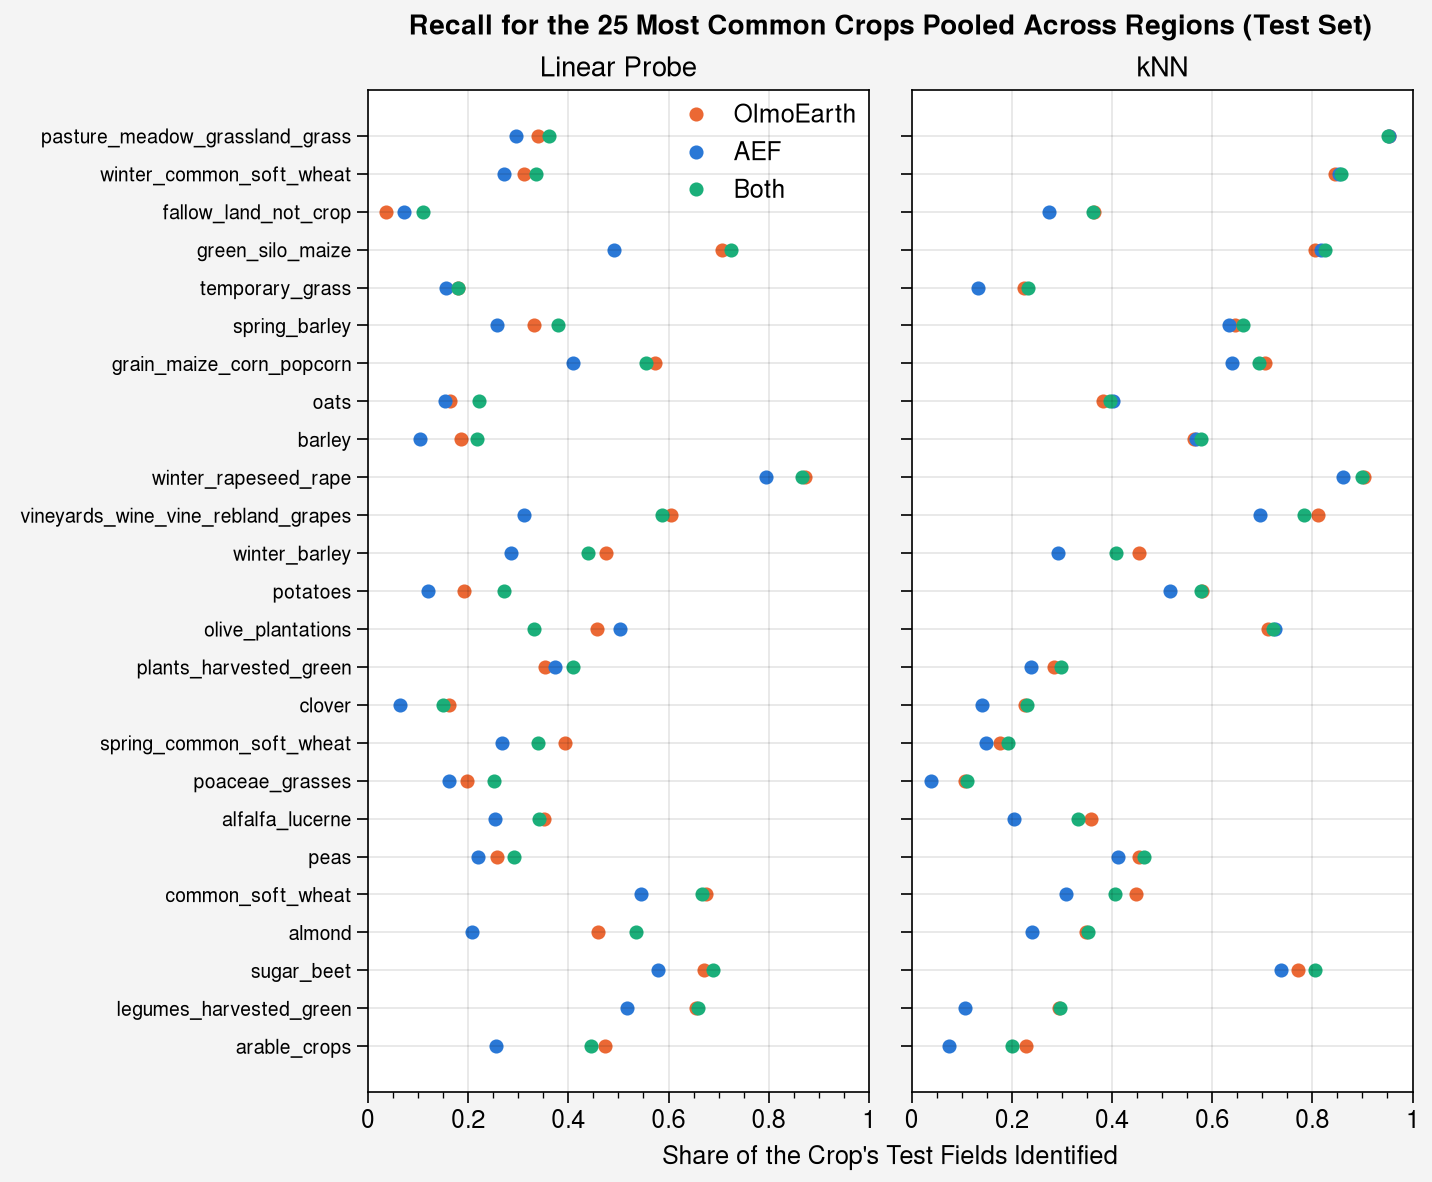

In [73]:
top    = predictions.crop.value_counts().head(TOPCROPS).index[::-1]
recall = pd.DataFrame({(method,featureset):recall_score(predictions.crop,predictions[f'{method}_{featureset}'],labels=top,average=None,zero_division=0)
                       for method,featureset in models},index=top)

fig,axs = uplt.subplots(ncols=2,refwidth=2.5,refheight=0.2*TOPCROPS,sharey=True)
for ax,method in zip(axs,METHODS):
    for featureset,name in FEATURESETS.items():
        ax.scatter(recall[(method,featureset)].to_numpy(),top.to_numpy(),color=COLORS[featureset],label=name,s=20)
    ax.format(title=METHODS[method],xlabel="Share of the Crop's Test Fields Identified",ylabel='',xlim=(0,1),ygrid=True,yticklabelsize=7)
axs[0].legend(loc='ur',ncols=1,frame=False)
fig.format(suptitle=f'Recall for the {TOPCROPS} Most Common Crops Pooled Across Regions (Test Set)')
fig.savefig(FIGDIR/'recall_by_crop.png',dpi=200)